# 06 Task 6: water quality sampling route
**Problem.** A technician starts at the node labelled office, must visit every node to take a sample, and returns to the office, walking along the pipes (the slides assume streets follow the pipe layout). Find a closed walk $W$ in $G$ that visits every vertex and minimises its total length. Nodes and pipes may be repeated, because the networks have no Hamiltonian cycle in general (NYT and HAN are nearly trees).

**Reduction.** Let $D$ be the metric closure: $D_{uv}=d_G(u,v)$ for all pairs. Any closed walk that visits every node, read as the order of first visits, is a tour of the complete graph on $D$ whose length is no larger than the walk's; conversely every tour of $D$ expands into a closed walk of the same length by replacing each step with its shortest path. So the minimum sampling walk equals the minimum TSP tour on $D$, and the walk is recovered by expansion.

**Input:** the instance, pipe lengths and the office node (every instance lists one in `[OFFICE]`: NYT 5, HAN 29, FOS 4, PES 51). **Output:** a closed walk over real pipes, its length, and whether it is proven optimal.

**Techniques.**
- *Dynamic programming:* Floyd-Warshall computes $D$ and a next-hop matrix in $O(V^3)$.
- *Greedy:* nearest neighbour builds a tour by always walking to the closest unvisited node, $O(n^2)$. No guarantee.
- *Local search:* 2-opt removes two tour legs and reconnects the tour the other way while that shortens it. Reaches a local optimum, no guarantee.
- *Branch and bound:* depth-first search over partial routes from the office, pruned with the bound below; exact, exponential in the worst case. Used on the full instances when it finishes, and on subsets of increasing size to measure the heuristics' gap.

Lower bound for a partial route ending at $u$ with unvisited set $R$: the cost so far, plus a minimum spanning tree of $R$, plus the cheapest leg from $u$ into $R$ and from $R$ back to the office. Any completion is a path through $R$ (at least the MST) plus those two legs, so the bound never overestimates and pruning never discards the optimum.

In [1]:
import os, sys
if 'google.colab' in sys.modules and not os.path.isdir('../water'):
    os.system('git clone -q https://github.com/santihdzs/water-distribution')
    os.chdir('water-distribution/notebooks')
sys.path.insert(0, os.path.abspath('..'))

import inspect
from collections import Counter
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import water
from water import paths, plot, tasks, tsp

plot.setup()
nets = water.load_all()
closure = {name: tasks.metric_closure(net) for name, net in nets.items()}

In [2]:
print(inspect.getsource(tsp.two_opt))
print(inspect.getsource(tsp.branch_and_bound))

def two_opt(D, tour):
    """first-improvement 2-opt: replace pipes (a,b),(c,d) by (a,c),(b,d) while that shortens the tour.
    position 0 (the office) never moves."""
    t = list(tour)
    n = len(t)
    moves, improved = 0, True
    while improved:
        improved = False
        for i in range(n - 2):
            a, b = t[i], t[i + 1]
            for j in range(i + 2, n if i else n - 1):
                c, d = t[j], t[(j + 1) % n]
                if D[a, c] + D[b, d] < D[a, b] + D[c, d] - 1e-9:
                    t[i + 1:j + 1] = t[i + 1:j + 1][::-1]
                    b = t[i + 1]
                    moves += 1
                    improved = True
    return t, moves

def branch_and_bound(D, start=0, incumbent=None, time_limit=None, node_limit=None):
    """exact depth-first branch and bound over partial routes from the office.
    bound(partial) = cost so far + mst(unvisited) + min pipe current->unvisited + min unvisited->office,
    which never exceeds the cost of any complet

## Correctness of the building blocks
Floyd-Warshall matches repeated Dijkstra (task 3 code) on every pair. Branch and bound matches exhaustive enumeration of all $(n-1)!$ orders on every subset with $n\le 9$.

In [3]:
from water import graph
for name, net in nets.items():
    D, nxt, ids, index = closure[name]
    adj = graph.adjacency_list(net)
    for u in ids:
        d, *_ = paths.dijkstra(adj, u)
        assert all(abs(D[index[u], index[v]] - d[v]) < 1e-9 for v in ids)
    o = index[net.office]
    order = list(np.argsort(D[o], kind='stable'))
    for k in range(3, 10):
        Ds = D[np.ix_(order[:k], order[:k])]
        _, c_bf = tsp.brute_force(Ds, 0)
        _, c_bb, proven, _, _ = tsp.branch_and_bound(Ds, 0)
        assert proven and abs(c_bf - c_bb) < 1e-6
print('floyd-warshall = repeated dijkstra; branch and bound = brute force for n = 3..9 on all instances')

floyd-warshall = repeated dijkstra; branch and bound = brute force for n = 3..9 on all instances


## Full instances
Nearest neighbour, then 2-opt from the nearest-neighbour tour, then branch and bound seeded with the 2-opt tour and stopped after 60 s. If the search finishes, its tour is proven optimal. If not, the reported route is the best tour found and the root lower bound brackets the optimum, so the gap to the optimum is at most (best minus bound) over bound.

In [4]:
full = {}
rows = []
for name, net in nets.items():
    D, nxt, ids, index = closure[name]
    o = index[net.office]
    nn = tsp.nearest_neighbor(D, o)
    t2, moves = tsp.two_opt(D, nn)
    best, cost, proven, root, st = tsp.branch_and_bound(D, o, t2, time_limit=60)
    walk = [ids[i] for i in tsp.expand(best, nxt, paths.fw_path)]

    # the walk must be closed, use only real pipes, cover every node, and have the tour's length
    pipes = {frozenset(p[:2]) for p in net.pipes}
    assert walk[0] == walk[-1] == net.office and set(walk) == set(ids)
    assert all(frozenset(e) in pipes for e in zip(walk, walk[1:]))
    assert abs(sum(net.length(a, b) for a, b in zip(walk, walk[1:])) - cost) < 1e-6

    uses = Counter(frozenset(e) for e in zip(walk, walk[1:]))
    full[name] = {'walk': walk, 'uses': uses, 'cost': cost, 'proven': proven}
    l_nn, l_2 = tsp.tour_length(D, nn), tsp.tour_length(D, t2)
    status = 'optimal' if proven else f'gap <= {(cost - root) / root:.1%}'
    print(f'{name}: NN {l_nn:,.1f} | NN + 2-opt {l_2:,.1f} ({moves} moves) | B&B {cost:,.1f} {status} '
          f'(root bound {root:,.1f}, {st["expanded"]:,} nodes expanded, {st["seconds"]:.1f} s)')
    print(f'      walk: {len(walk) - 1} pipe traversals for {len(ids)} nodes, '
          f'{sum(1 for c in uses.values() if c > 1)} pipes walked twice, '
          f'{len(pipes) - len(uses)} of {len(pipes)} pipes never walked')
    # against a proven optimum the gap is exact; against the root bound it is only an upper limit
    gap = f'{(l_2 - cost) / cost:.1%}' if proven else f'$\\le$ {(l_2 - root) / root:.1%}'
    rows.append([name, len(ids), l_nn, l_2, cost, 'optimal' if proven else 'best found', root, gap, len(walk) - 1])

plot.table('routes', rows,
           ['Inst.', '$n$', 'NN', 'NN + 2-opt', 'B\\&B', 'Status', 'Lower bound', 'NN + 2-opt gap', 'Walk pipes'],
           ['{}', '{}', '{:,.0f}', '{:,.0f}', '{:,.0f}', '{}', '{:,.0f}', '{}', '{}'])
for name in nets:
    print(f'\n{name} walk ({len(full[name]["walk"]) - 1} pipe traversals, length {full[name]["cost"]:,.1f}):',
          '-'.join(map(str, full[name]['walk'])))
plot.table('walks', [[name, f'{full[name]["cost"]:,.0f}', '-\\allowbreak '.join(map(str, full[name]['walk']))] for name in nets],
           ['Inst.', 'Length', 'Closed walk from the office'], ['{}', '{}', '{}'])

NYT: NN 9,581.4 | NN + 2-opt 7,622.3 (3 moves) | B&B 7,072.1 optimal (root bound 5,534.8, 5,540 nodes expanded, 1.2 s)
      walk: 24 pipe traversals for 20 nodes, 4 pipes walked twice, 1 of 21 pipes never walked


HAN: NN 43,802.1 | NN + 2-opt 40,810.0 (1 moves) | B&B 40,810.0 gap <= 33.3% (root bound 30,605.2, 117,788 nodes expanded, 60.0 s)
      walk: 43 pipe traversals for 32 nodes, 11 pipes walked twice, 2 of 34 pipes never walked


FOS: NN 40,129.9 | NN + 2-opt 30,424.3 (4 moves) | B&B 30,424.3 gap <= 21.0% (root bound 25,147.3, 74,736 nodes expanded, 60.0 s)
      walk: 41 pipe traversals for 37 nodes, 4 pipes walked twice, 21 of 58 pipes never walked


PES: NN 38,604.2 | NN + 2-opt 35,510.1 (11 moves) | B&B 35,510.1 gap <= 60.0% (root bound 22,195.1, 155,167 nodes expanded, 60.2 s)
      walk: 97 pipe traversals for 71 nodes, 23 pipes walked twice, 24 of 98 pipes never walked

NYT walk (24 pipe traversals, length 7,072.1): 5-4-3-2-1-15-14-13-12-18-19-18-12-11-20-16-9-10-17-10-9-8-7-6-5

HAN walk (43 pipe traversals, length 40,810.0): 29-28-23-20-21-22-21-20-3-2-1-2-3-19-18-17-18-19-3-4-5-6-7-8-9-10-11-12-13-12-11-10-14-15-16-27-26-25-24-25-32-31-30-29

FOS walk (41 pipe traversals, length 30,424.3): 4-5-13-14-20-14-21-6-7-24-8-28-29-30-9-36-35-34-33-34-31-1-37-1-17-2-3-2-18-10-32-27-16-25-23-22-15-26-11-19-12-4

PES walk (97 pipe traversals, length 35,510.1): 51-48-47-56-57-58-62-59-62-2-4-3-1-3-5-61-60-61-55-86-55-54-84-88-89-53-52-45-52-50-46-32-49-32-31-37-38-19-20-21-23-22-85-82-83-26-27-26-17-24-25-12-39-34-41-40-9-33-30-28-29-8-76-65-6-7-6-8-29-35-36-35-25-24-14-15-14-24-17-13-18-19-38-37-31-11-10-11-42-43-87-43-42-44-56-47-48-

NYT (20 nodes) is solved exactly in about a second. For HAN, FOS and PES the search does not finish in 60 s; the NN + 2-opt route is the best found and the MST-based root bound is too weak to close the gap, because it counts each connection once while the walk must come back out of every dead end (HAN needs 43 traversals of its 34 pipes). These routes are therefore approximate, with the optimality gap bounded only loosely by the "NN + 2-opt gap" column (an upper bound when not optimal).

## Heuristic gap on subsets of increasing size
To measure how far the heuristics are from the optimum where the optimum is computable, the problem is restricted to the $k$ nodes closest to the office (by network distance, office included), walking on the full network. For $k=4,6,\dots$ branch and bound is run until a subset needs more than 100,000 search nodes, or does not finish within a budget of 300,000. Counting search nodes instead of seconds makes the set of solved subsets independent of the machine.

In [5]:
subsets = []
for name, net in nets.items():
    D, nxt, ids, index = closure[name]
    o = index[net.office]
    order = list(np.argsort(D[o], kind='stable'))
    for k in range(4, len(ids) + 1, 2):
        Ds = D[np.ix_(order[:k], order[:k])]
        nn = tsp.nearest_neighbor(Ds, 0)
        t2, _ = tsp.two_opt(Ds, nn)
        _, opt, proven, _, st = tsp.branch_and_bound(Ds, 0, t2, node_limit=300_000)
        if not proven:
            break
        subsets.append({'inst': name, 'k': k, 'opt': opt, 'nn': tsp.tour_length(Ds, nn),
                        't2': tsp.tour_length(Ds, t2), 'seconds': st['seconds'], 'expanded': st['expanded']})
        if st['expanded'] > 100_000:
            break
    done = [s for s in subsets if s['inst'] == name]
    print(f'{name}: solved k = 4..{done[-1]["k"]} | NN gap mean {np.mean([s["nn"]/s["opt"]-1 for s in done]):.1%}, '
          f'max {max(s["nn"]/s["opt"]-1 for s in done):.1%} | NN + 2-opt gap mean {np.mean([s["t2"]/s["opt"]-1 for s in done]):.1%}, '
          f'max {max(s["t2"]/s["opt"]-1 for s in done):.1%} | optimal reached by NN + 2-opt in '
          f'{sum(s["t2"] - s["opt"] < 1e-6 for s in done)} of {len(done)}')

gaps_nn = [s['nn'] / s['opt'] - 1 for s in subsets]
gaps_2 = [s['t2'] / s['opt'] - 1 for s in subsets]
print(f'\nall {len(subsets)} solved subsets: NN mean gap {np.mean(gaps_nn):.1%}, NN + 2-opt mean gap {np.mean(gaps_2):.1%}, '
      f'NN + 2-opt optimal in {sum(g < 1e-9 for g in gaps_2)}')

NYT: solved k = 4..20 | NN gap mean 16.0%, max 35.5% | NN + 2-opt gap mean 0.9%, max 7.8% | optimal reached by NN + 2-opt in 8 of 9


HAN: solved k = 4..24 | NN gap mean 19.1%, max 37.8% | NN + 2-opt gap mean 1.9%, max 10.1% | optimal reached by NN + 2-opt in 8 of 11


FOS: solved k = 4..26 | NN gap mean 19.3%, max 37.8% | NN + 2-opt gap mean 3.8%, max 15.8% | optimal reached by NN + 2-opt in 7 of 12


PES: solved k = 4..18 | NN gap mean 6.9%, max 16.9% | NN + 2-opt gap mean 0.0%, max 0.0% | optimal reached by NN + 2-opt in 8 of 8

all 40 solved subsets: NN mean gap 16.0%, NN + 2-opt mean gap 1.9%, NN + 2-opt optimal in 31


## Figure

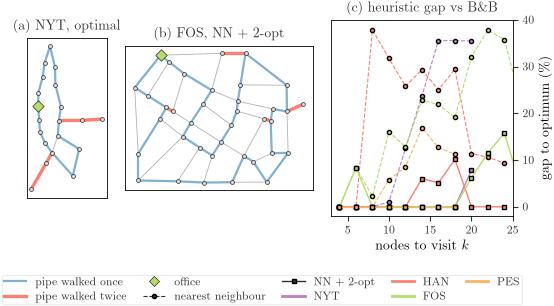

In [6]:
fig = plt.figure(figsize=(6.27, 2.55))
gs = fig.add_gridspec(1, 3, width_ratios=[0.55, 1.3, 1.25], wspace=0.12)
for k, name in enumerate(['NYT', 'FOS']):
    ax = fig.add_subplot(gs[k])
    net, r = nets[name], full[name]
    plot.pipes(ax, net, color=plot.GRID, lw=0.6)
    once = [p for p in net.pipes if r['uses'].get(frozenset(p[:2])) == 1]
    twice = [p for p in net.pipes if r['uses'].get(frozenset(p[:2]), 0) > 1]
    plot.pipes(ax, net, once, color=plot.SECTOR[1], lw=1.6)
    plot.pipes(ax, net, twice, color=plot.HIGHLIGHT, lw=2.4)
    plot.nodes(ax, net, s=8)
    plot.office(ax, net)
    status = 'optimal' if r['proven'] else 'NN + 2-opt'
    plot.frame(ax, f'({"ab"[k]}) {name}, {status}')
ax = fig.add_subplot(gs[2])
for j, name in enumerate(nets):
    s = [x for x in subsets if x['inst'] == name]
    ax.plot([x['k'] for x in s], [100 * (x['nn'] / x['opt'] - 1) for x in s], 'o--', ms=3, color=plot.PALETTE[j], lw=0.8)
    ax.plot([x['k'] for x in s], [100 * (x['t2'] / x['opt'] - 1) for x in s], 's-', ms=3, color=plot.PALETTE[j], lw=1.0, label=name)
ax.set(xlabel='nodes to visit $k$', ylabel=r'gap to optimum (\%)', title='(c) heuristic gap vs B\\&B')
ax.yaxis.set_label_position('right'); ax.yaxis.tick_right()
ax.set_ylim(-2, 40)
ax.set_xlim(3, 25)
h = [plt.Line2D([], [], color=plot.SECTOR[1], lw=1.6, label='pipe walked once'),
     plt.Line2D([], [], color=plot.HIGHLIGHT, lw=2.4, label='pipe walked twice'),
     plt.Line2D([], [], ls='', marker='D', mfc=plot.OFFICE, mec='k', mew=0.4, ms=5, label='office'),
     plt.Line2D([], [], color=plot.INK, ls='--', marker='o', ms=3, lw=0.8, label='nearest neighbour'),
     plt.Line2D([], [], color=plot.INK, ls='-', marker='s', ms=3, lw=1.0, label='NN + 2-opt'),
     *[plt.Line2D([], [], color=plot.PALETTE[j], lw=2, label=n) for j, n in enumerate(nets)]]
fig.legend(handles=h, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5)
plot.save(fig, 'routes')
plt.show()

## Complexity
Floyd-Warshall: $O(V^3)$ time, $O(V^2)$ space. Nearest neighbour: $O(n^2)$. One 2-opt pass: $O(n^2)$ move evaluations, repeated until no improving move (the number of passes is not polynomially bounded in theory but was at most a handful here). Branch and bound: $O(n!)$ partial routes in the worst case, each bounded in $O(n^2)$ by Prim's MST; the bound prunes most of them, but the work still grows exponentially with $n$ (measured in `08_performance`). Expansion of the tour into a walk: $O(\text{walk length})$ with the next-hop matrix.

## Optimal versus approximate
- NYT: the route of length 7,072 is **optimal** (branch and bound finished).
- HAN, FOS, PES: the routes are **approximate** (NN + 2-opt local optima); branch and bound could not prove optimality in 60 s.
- On the 40 subsets where the optimum is known, nearest neighbour alone is on average 16.0% above it (worst 37.8%), and NN + 2-opt reduces that to 1.9% (worst 15.8%), reaching the optimum in 31 of them.

## Interpretation
Because the networks are sparse, the technician must walk many pipes twice: the optimal NYT route walks 7,072 units over a network whose pipes total 6,020, and dead ends such as the branches to the sources force a there-and-back. On the full instances the greedy nearest-neighbour route is 7% (HAN) to 32% (FOS) longer than the NN + 2-opt route, and 2-opt recovers that difference with between 1 and 11 improving moves.